In [368]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

In [326]:
# Loading the dataset
df = pd.read_csv('space_missions.csv', encoding='iso-8859-1')
df.head()

,Company,Location,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus
0,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,NaN,Success
1,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,NaN,Success
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,NaN,Failure
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,NaN,Success
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,NaN,Failure


In [327]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4630 entries, 0 to 4629
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Company        4630 non-null   str  
 1   Location       4630 non-null   str  
 2   Date           4630 non-null   str  
 3   Time           4503 non-null   str  
 4   Rocket         4630 non-null   str  
 5   Mission        4630 non-null   str  
 6   RocketStatus   4630 non-null   str  
 7   Price          1265 non-null   str  
 8   MissionStatus  4630 non-null   str  
dtypes: str(9)
memory usage: 325.7 KB


In [328]:
# Converting the Date column into datetime and time column into numeric
df['Date'] = pd.to_datetime(df['Date'], format= '%Y-%m-%d')
df['Time'] = pd.to_datetime(df['Time'], format= '%H:%M:%S').dt.time

In [329]:
# remove the , in the price column and then convert it to float
df['Price'] = df['Price'].astype(str).str.replace(',', '').str.strip()
df['Price'] = pd.to_numeric(df['Price'])

In [330]:
df.head()

,Company,Location,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus
0,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,NaN,Success
1,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,NaN,Success
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,NaN,Failure
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,NaN,Success
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,NaN,Failure


In [331]:
mean_price = df['Price'].mean()
df['Price'] = df['Price'].fillna(mean_price)
# df = df.dropna()

In [332]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4630 entries, 0 to 4629
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Company        4630 non-null   str           
 1   Location       4630 non-null   str           
 2   Date           4630 non-null   datetime64[us]
 3   Time           4503 non-null   object        
 4   Rocket         4630 non-null   str           
 5   Mission        4630 non-null   str           
 6   RocketStatus   4630 non-null   str           
 7   Price          4630 non-null   float64       
 8   MissionStatus  4630 non-null   str           
dtypes: datetime64[us](1), float64(1), object(1), str(6)
memory usage: 325.7+ KB


In [333]:
# Add decade and Country columns
df['Decade'] = (df['Date'].dt.year // 10) * 10


countries_replace = {
    'Russia' : 'Russian Federation',
    'New Mexico' : 'USA',
    "Yellow Sea": 'China',
    "Shahrud Missile Test Site": "Iran",
    "Pacific Missile Range Facility": 'USA',
    "Barents Sea": 'Russian Federation',
    "Gran Canaria": 'USA'
}
df['Country'] = df['Location'].str.split(',').str[-1].str.strip().replace(countries_replace)

In [334]:
# Extract State and Launchpad from Location and drop Location

# Extract the launch pad (always the first item)
df['LaunchPad'] = df['Location'].str.split(',').str[0].str.strip()

# Extract the state/province dynamically (always the second-to-last item)
# This handles dynamic lengths whether the location has 3, 4, or 5 commas
df['State'] = df['Location'].apply(
    lambda x: x.split(',')[-2].strip() if len(x.split(',')) > 1 else 'Unknown'
)
df.drop('Location', axis=1)

,Company,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus,Decade,Country,LaunchPad,State
0,RVSN USSR,1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,128.303913,Success,1950,Kazakhstan,Site 1/5,Baikonur Cosmodrome
1,RVSN USSR,1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,128.303913,Success,1950,Kazakhstan,Site 1/5,Baikonur Cosmodrome
2,US Navy,1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,128.303913,Failure,1950,USA,LC-18A,Florida
3,AMBA,1958-02-01,03:48:00,Juno I,Explorer 1,Retired,128.303913,Success,1950,USA,LC-26A,Florida
4,US Navy,1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,128.303913,Failure,1950,USA,LC-18A,Florida
...,...,...,...,...,...,...,...,...,...,...,...,...
4625,SpaceX,2022-07-22,17:39:00,Falcon 9 Block 5,Starlink Group 3-2,Active,67.000000,Success,2020,USA,SLC-4E,California
4626,CASC,2022-07-24,06:22:00,Long March 5B,Wentian,Active,128.303913,Success,2020,China,LC-101,Wenchang Satellite Launch Center
4627,SpaceX,2022-07-24,13:38:00,Falcon 9 Block 5,Starlink Group 4-25,Active,67.000000,Success,2020,USA,LC-39A,Florida
4628,CAS Space,2022-07-27,04:12:00,Zhongke-1A,Demo Flight,Active,128.303913,Success,2020,China,Jiuquan Satellite Launch Center,Jiuquan Satellite Launch Center


In [335]:
# Calculate Success Rate
company_stats = df.groupby('Company', as_index=False).agg(total_launches=('MissionStatus', 'count'),
    success_rate=('MissionStatus', lambda x: (x == 'Success').mean() * 100)).sort_values(by='total_launches', ascending=False).reset_index()

company_stats.head()

,index,Company,total_launches,success_rate
0,45,RVSN USSR,1777,90.827237
1,9,CASC,338,94.082840
2,3,Arianespace,293,96.245734
3,22,General Dynamics,251,80.876494
4,57,VKS RF,216,93.518519


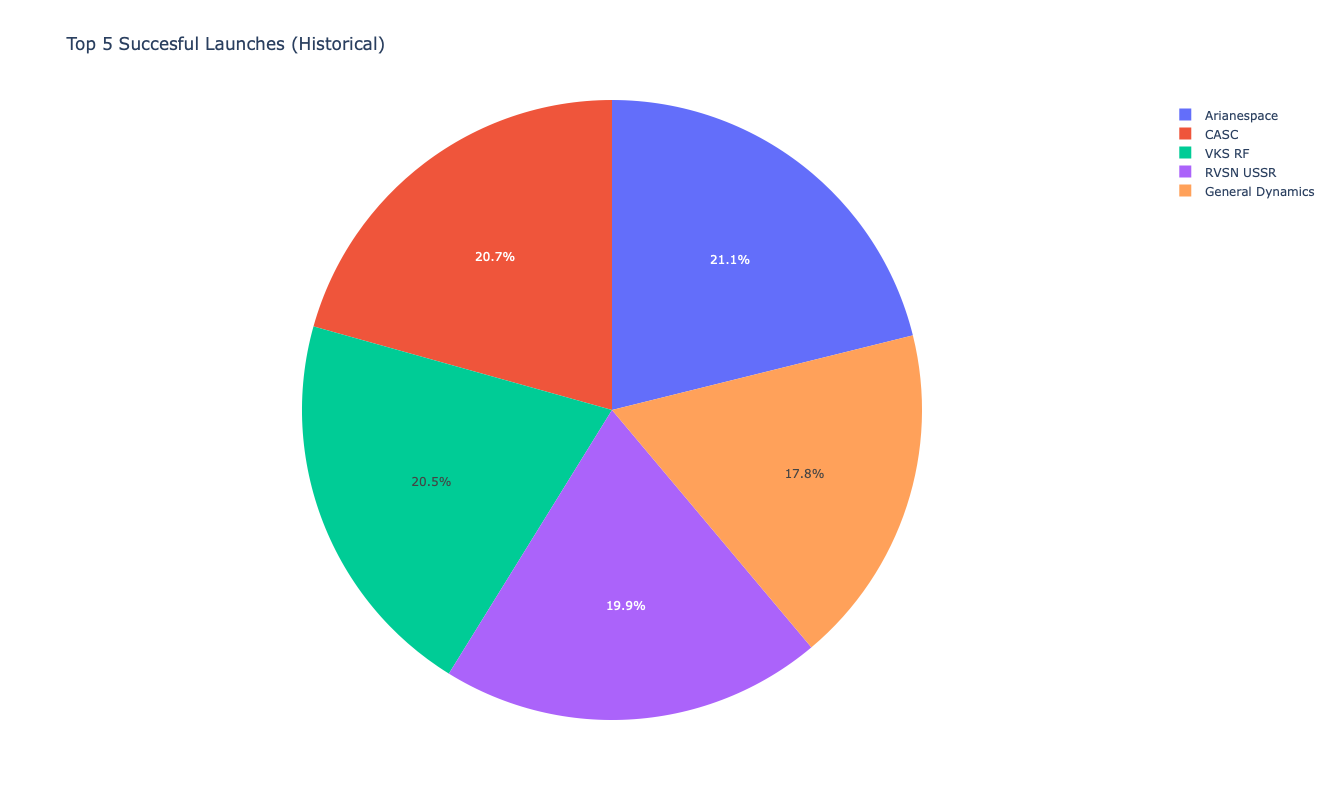

In [397]:
# get the top 5 success rate
top5_success = company_stats.head(5).copy()

# explode = [0.2, 0.0, 0.0,0.0,0.0]
# plt.figure(figsize= (10,6))
# plt.pie(top5_success['success_rate'], labels = top5_success['Company'], explode=explode)
# plt.title('Top 5 Succesful Launches (Historical)', fontsize=15, fontweight='bold', pad=15)
# plt.legend()
# plt.show()

fig = px.pie(top5_success, values = 'success_rate', names = 'Company', title='Top 5 Succesful Launches (Historical)')
fig.update_layout(
    width=800,
    height=800
)
fig.show()

In [337]:
# Calculate Total Price for each Country
country_spending = df.groupby('Country')['Price'].sum().reset_index()
country_spending = country_spending.sort_values(by='Price', ascending=False).reset_index(drop=True)
country_spending.head()

,Country,Price
0,USA,225563.047826
1,Russia,173958.980000
2,Kazakhstan,96098.499130
3,France,42537.743478
4,China,23703.164348


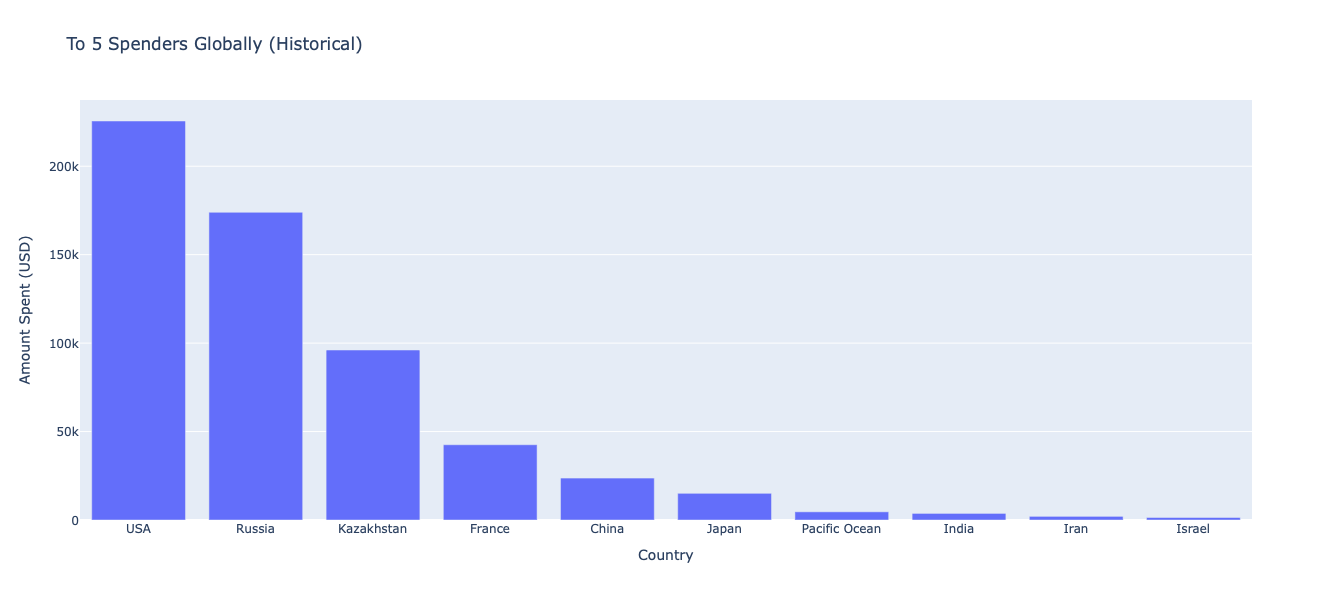

In [395]:
# Extract the top 10 spenders
top5_spenders = country_spending.head(10).copy()

# plot in a bar chart

fig = px.bar(top5_spenders,'Country', 'Price', title='To 5 Spenders Globally (Historical)')
fig.update_layout(width = 1400, 
                  height = 600,
                 xaxis_title="Country",
                 yaxis_title="Amount Spent (USD)")
fig.show()

In [339]:
# convert some column to categoric
df['Company'] = df['Company'].astype('category')
df['RocketStatus'] = df['RocketStatus'].astype('category')
df['Rocket'] = df['Rocket'].astype('category')

In [340]:
df.head()

,Company,Location,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus,Decade,Country,LaunchPad,State
0,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,128.303913,Success,1950,Kazakhstan,Site 1/5,Baikonur Cosmodrome
1,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,128.303913,Success,1950,Kazakhstan,Site 1/5,Baikonur Cosmodrome
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,128.303913,Failure,1950,USA,LC-18A,Florida
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,128.303913,Success,1950,USA,LC-26A,Florida
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,128.303913,Failure,1950,USA,LC-18A,Florida


In [341]:
# Calculate Worst Rocket Failures

# Filter out experimental models by setting a launch threshold
min_launches = 5

# Group by the rocket name ('Rocket') and evaluate the outcome ('MissionStatus')
worst_rockets = df.groupby('Rocket').agg(
    total_launches=('MissionStatus', 'count'),
    # Count how many times it equals 'failure' and get the percentage
    failure_rate=('MissionStatus', lambda x: (x == 'Failure').mean() * 100)
).reset_index()

# Apply the minimum launch volume filter and sort from worst to best
worst_rockets = worst_rockets[worst_rockets['total_launches'] >= min_launches]
worst_rockets = worst_rockets.sort_values(by='failure_rate', ascending=False).reset_index(drop=True)

# Display your final top 10 worst rocket models
worst_rockets.head()

,Rocket,total_launches,failure_rate
0,NOTS-EV-1 Pilot II,6,100.000000
1,Lambda-IV S,5,80.000000
2,Vanguard,11,72.727273
3,Rocket 3,7,71.428571
4,Safir-1B+,6,66.666667


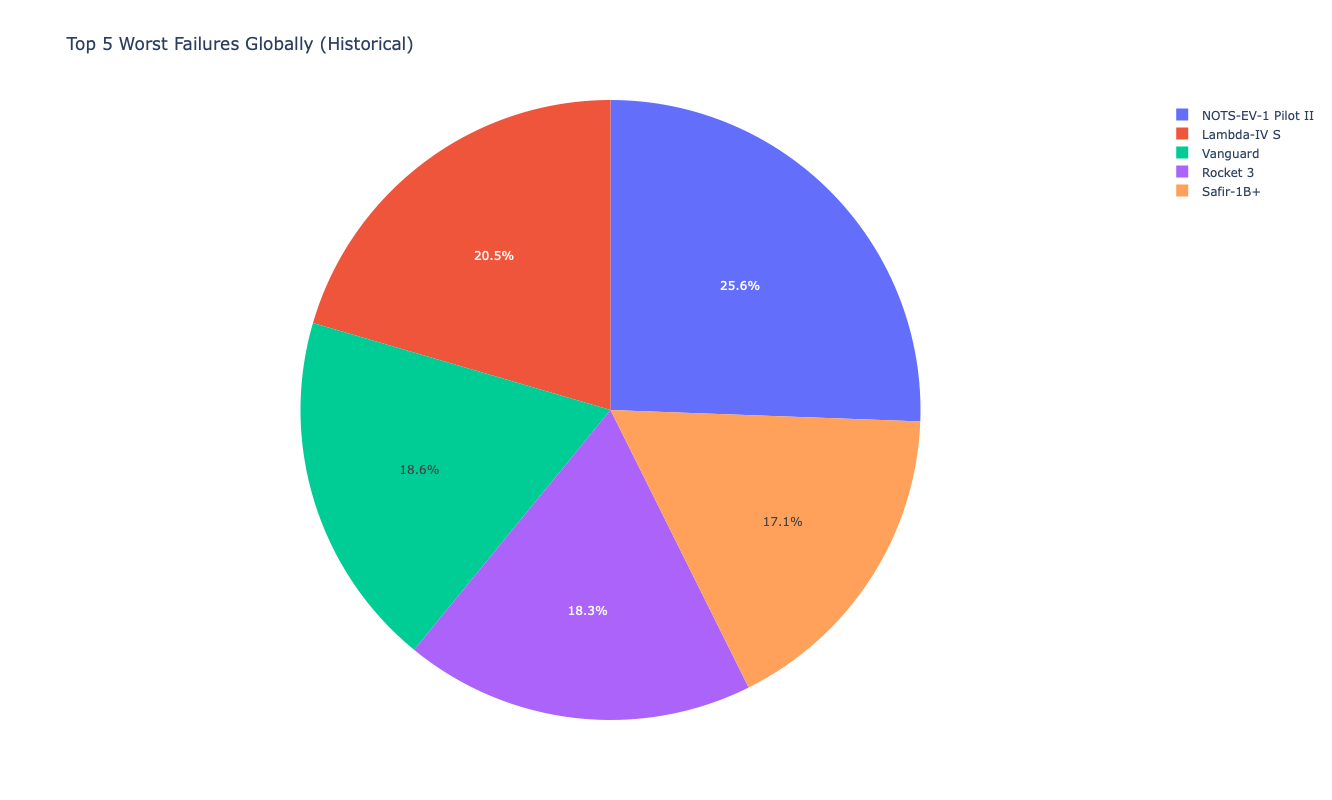

In [389]:
# get the top 10 success rate
top5_failure = worst_rockets.head(5).copy()

fig = px.pie(top5_failure, values = 'failure_rate', names = 'Rocket', title='Top 5 Worst Failures Globally (Historical)')
fig.update_layout(
    width=800,
    height=800
)
fig.show()

In [343]:
# States with highest Rocket Launches

# Group by Country and State together so you know exactly where each territory belongs
state_launch_counts = df.groupby(['Country', 'State']).size().reset_index(name='Total_Launches')

# Sort from highest number of launches to lowest
state_launch_counts = state_launch_counts.sort_values(by='Total_Launches', ascending=False)

# Drop old index
state_launch_counts = state_launch_counts.reset_index(drop=True)

state_launch_counts.head()

,Country,State,Total_Launches
0,Russia,Plesetsk Cosmodrome,1278
1,USA,Florida,911
2,Kazakhstan,Baikonur Cosmodrome,719
3,USA,California,473
4,France,French Guiana,314


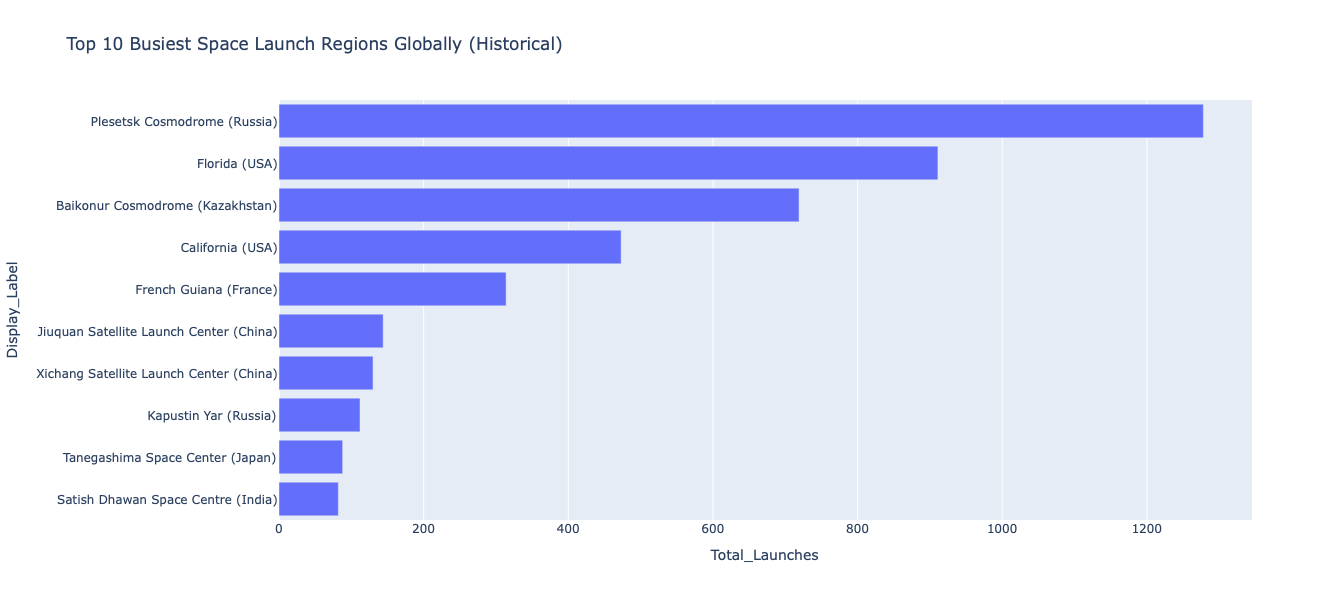

In [384]:
import matplotlib.pyplot as plt

# Grab the top 10 busiest space regions from your aggregated dataframe
top_10_regions = state_launch_counts.head(10).copy()

# Create a clean display label combining State and Country (e.g., "Florida (USA)")
top_10_regions['Display_Label'] = top_10_regions['State'] + ' (' + top_10_regions['Country'] + ')'

# Reverse the order so the absolute #1 region is plotted at the very top of the chart
top_10_regions = top_10_regions.iloc[::-1]



fig = px.bar(top_10_regions, 'Total_Launches','Display_Label', orientation='h', title= 'Top 10 Busiest Space Launch Regions Globally (Historical)')
fig.update_layout(
    width = 1200,
    height = 600)
fig.show()


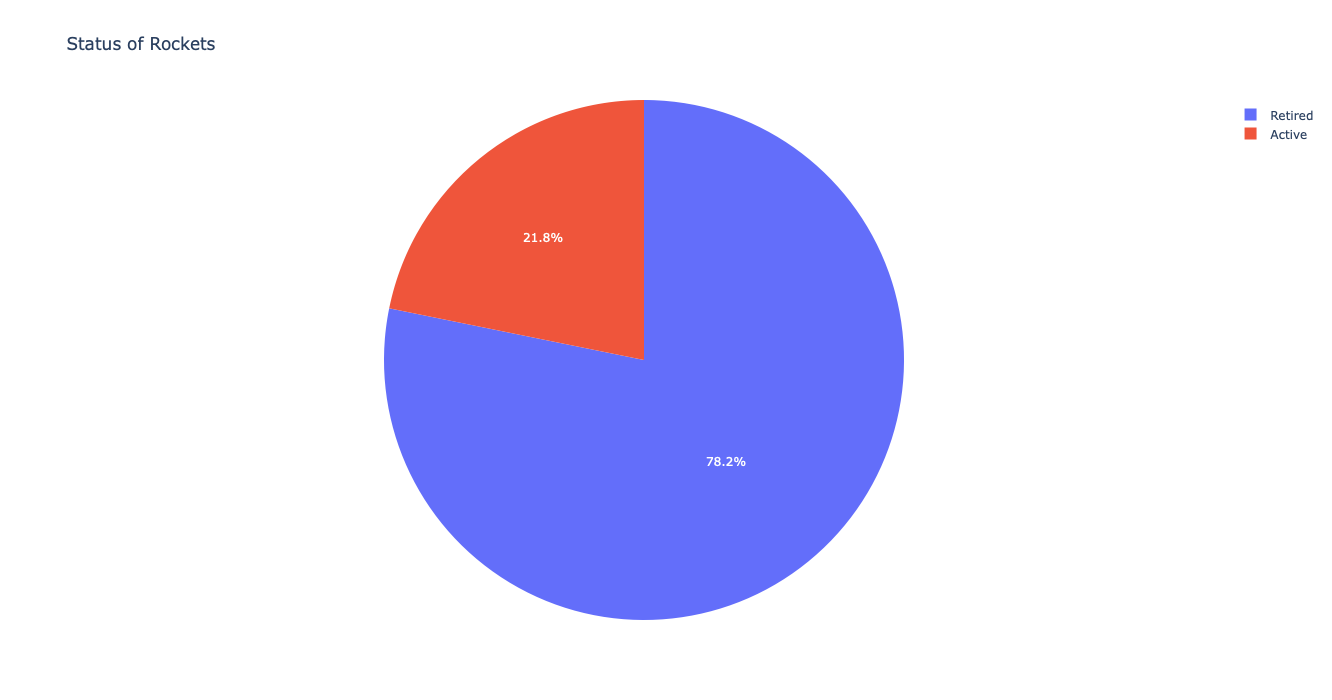

In [391]:
fig = px.pie(rocket_status, values ='count', names = 'RocketStatus', title='Status of Rockets')
fig.update_layout(
    width=700,
    height=700
)
fig.show()

In [362]:
df_usa = df[df['Country']== 'USA']

In [346]:
df_usa.head()

,Company,Location,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus,Decade,Country,LaunchPad,State
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,128.303913,Failure,1950,USA,LC-18A,Florida
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,128.303913,Success,1950,USA,LC-26A,Florida
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,128.303913,Failure,1950,USA,LC-18A,Florida
5,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-03-05,18:27:00,Juno I,Explorer 2,Retired,128.303913,Failure,1950,USA,LC-26A,Florida
6,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-03-17,12:15:00,Vanguard,Vanguard 1,Retired,128.303913,Success,1950,USA,LC-18A,Florida


In [347]:
df_usa['Year'] = df_usa['Date'].dt.year

In [348]:
df_usa.head()

,Company,Location,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus,Decade,Country,LaunchPad,State,Year
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,128.303913,Failure,1950,USA,LC-18A,Florida,1957
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,128.303913,Success,1950,USA,LC-26A,Florida,1958
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,128.303913,Failure,1950,USA,LC-18A,Florida,1958
5,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-03-05,18:27:00,Juno I,Explorer 2,Retired,128.303913,Failure,1950,USA,LC-26A,Florida,1958
6,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-03-17,12:15:00,Vanguard,Vanguard 1,Retired,128.303913,Success,1950,USA,LC-18A,Florida,1958
